# 00 — Environment and corpus

## Objective

Establish a reproducible notebook environment and inspect the documents available to the project before implementing any document-processing logic.

By the end, we should know which Python kernel is running, where the repository root is, which PDF files are registered, and whether the recorded page counts match the files.

## Concept

A reproducible experiment starts by making inputs and assumptions visible. Hidden paths, an unexpected kernel, or a stale corpus manifest can invalidate every later result. The CSV manifest is treated as the declared corpus; the PDF files are the observed corpus.

In [1]:
from pathlib import Path
import platform
import sys

import matplotlib.pyplot as plt
import pandas as pd
import pymupdf

plt.style.use("seaborn-v0_8-whitegrid")

## Implementation — locate the project

The notebook may be started from the repository root or from this directory, so we search upward for `pyproject.toml` instead of relying on the current working directory.

In [2]:
def find_project_root(start=Path.cwd()):
    """Return the nearest parent containing pyproject.toml."""
    for candidate in (start, *start.parents):
        if (candidate / "pyproject.toml").is_file():
            return candidate
    raise FileNotFoundError("Could not find the repository root")


PROJECT_ROOT = find_project_root()
DOCUMENTS_CSV = PROJECT_ROOT / "data" / "annotations" / "documents.csv"

print("Repository root:", PROJECT_ROOT)
print("Python:", sys.version.split()[0])
print("Executable:", sys.executable)
print("Platform:", platform.platform())
print("PyMuPDF:", pymupdf.__version__)

Repository root: /Users/macbookair/Documents/ENSAE/side project/Multimodal-Document-Intelligence
Python: 3.12.6
Executable: /Library/Frameworks/Python.framework/Versions/3.12/bin/python3
Platform: macOS-26.5.2-arm64-arm-64bit
PyMuPDF: 1.27.2


## Execution — read and reconcile the corpus manifest

We compare the declared page count with the count reported by PyMuPDF. A mismatch would mean that annotations and physical page citations may refer to the wrong pages.

In [3]:
documents = pd.read_csv(DOCUMENTS_CSV)

observed_rows = []
for row in documents.itertuples(index=False):
    pdf_path = PROJECT_ROOT / row.file_path
    with pymupdf.open(pdf_path) as document:
        observed_page_count = document.page_count
    observed_rows.append(
        {
            "doc_id": row.doc_id,
            "title": row.title,
            "source_kind": row.source_kind,
            "status": row.status,
            "declared_pages": row.page_count,
            "observed_pages": observed_page_count,
            "file_exists": pdf_path.is_file(),
        }
    )

corpus_check = pd.DataFrame(observed_rows)
corpus_check

,doc_id,title,source_kind,status,declared_pages,observed_pages,file_exists
0,D001,"The prior distribution (Bayesian statistics, c...",born_digital,candidate,68,68,True
1,D002,EPA sample letter on drinking water (scanned),scanned,candidate,3,3,True
2,D003,"Apple Inc. Form 10-K, fiscal year ended 2023-0...",born_digital,candidate,74,74,True


## Inspection — corpus size

A horizontal bar chart makes the large difference in document sizes visible without implying that page count measures document quality or difficulty.

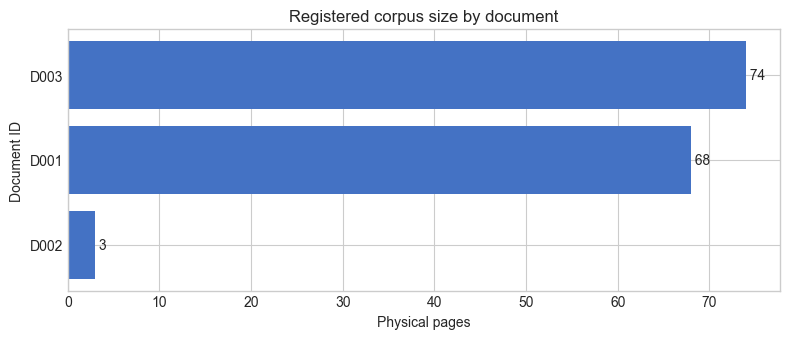

In [4]:
plot_data = corpus_check.sort_values("observed_pages")
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.barh(plot_data["doc_id"], plot_data["observed_pages"], color="#4472C4")
ax.set_title("Registered corpus size by document")
ax.set_xlabel("Physical pages")
ax.set_ylabel("Document ID")
for y_position, page_count in enumerate(plot_data["observed_pages"]):
    ax.text(page_count, y_position, f" {page_count}", va="center")
plt.tight_layout()
plt.show()

## Interpretation

The manifest is the source of document identity and metadata, while PyMuPDF supplies the observed page count. Later notebooks should retain `doc_id`, the relative file path, and 1-based physical page numbers in every page record.

## Validation

In [5]:
assert not corpus_check.empty, "The document manifest is empty"
assert corpus_check["file_exists"].all(), "At least one registered PDF is missing"
assert (corpus_check["declared_pages"] == corpus_check["observed_pages"]).all(), (
    "A declared page count does not match its PDF"
)
assert documents["doc_id"].is_unique, "Document IDs must be unique"

print(f"Validated {len(corpus_check)} registered documents.")

Validated 3 registered documents.


## Next step

Open `01_pdf_representation.ipynb` to inspect what a born-digital page and a scanned page actually contain.